In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
import seaborn as sns

df = pd.read_csv('data/supermarket.csv')

# Mengonversi kolom 'Date' menjadi tipe datetime
df['Date'] = pd.to_datetime(df['Date'])

df.head()

ImportError: dlopen(/Users/suniantara/Documents/Project/Python/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/_representation.cpython-312-darwin.so, 0x0002): symbol not found in flat namespace '_npy_cabs'

In [4]:
# Menambahkan kolom total penjualan (Unit price * Quantity)

df['Total Sales'] = df['Unit price'] * df['Quantity']

df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Date,Time,Payment,Rating,Total Sales
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,2019-01-05,13:08,Ewallet,9.1,522.83
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,2019-03-08,10:29,Cash,9.6,76.40
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,2019-03-03,13:23,Credit card,7.4,324.31
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,2019-01-27,20:33,Ewallet,8.4,465.76
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,2019-02-08,10:37,Ewallet,5.3,604.17


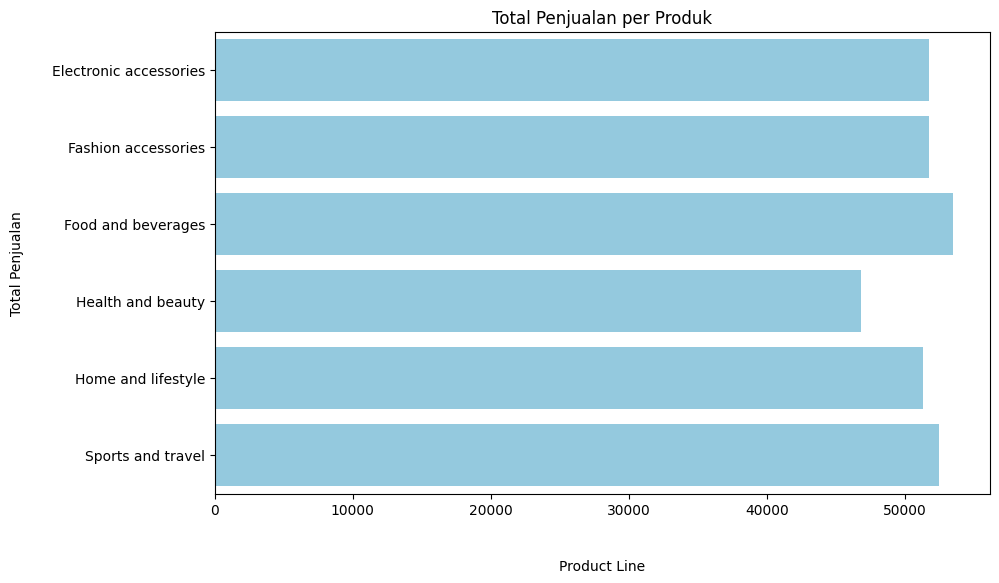

In [5]:
# Visualisasi Total Penjualan per Produk
product_sales = df.groupby('Product line')['Total Sales'].sum()

plt.figure(figsize=(10, 6))
sns.barplot(x = product_sales.values, y = product_sales.index, color='skyblue')
plt.title('Total Penjualan per Produk')
plt.ylabel('Total Penjualan', labelpad=20)
plt.xlabel('Product Line', labelpad=30)
plt.show()

In [6]:
# Menyusun data penjualan berdasarkan tanggal
df_sales = df[['Date', 'Total Sales']].set_index('Date').resample('D').sum()
df_sales

,Total Sales
Date,
2019-01-01,4519.22
2019-01-02,1852.86
2019-01-03,1979.17
2019-01-04,1546.37
2019-01-05,3368.27
...,...
2019-03-26,1869.06
2019-03-27,2764.59
2019-03-28,2123.24


In [7]:
# Menyusun data penjualan berdasarkan tanggal
df_sales = df[['Date', 'Total Sales']].set_index('Date').resample('D').sum()
df_sales

# Melakukan forecasting dengan ARMA
model = ARIMA(df_sales, order=(5, 1, 0))
model_fit = model.fit()

# Menentukan periode untuk forecasting (10 hari ke depan)
forecast = model_fit.forecast(steps=10)
forecast


2019-03-31    2571.211019
2019-04-01    2828.824552
2019-04-02    3179.321169
2019-04-03    3404.522319
2019-04-04    3320.169597
2019-04-05    3044.302492
2019-04-06    3076.441935
2019-04-07    3218.484111
2019-04-08    3246.086596
2019-04-09    3188.963827
Freq: D, Name: predicted_mean, dtype: float64

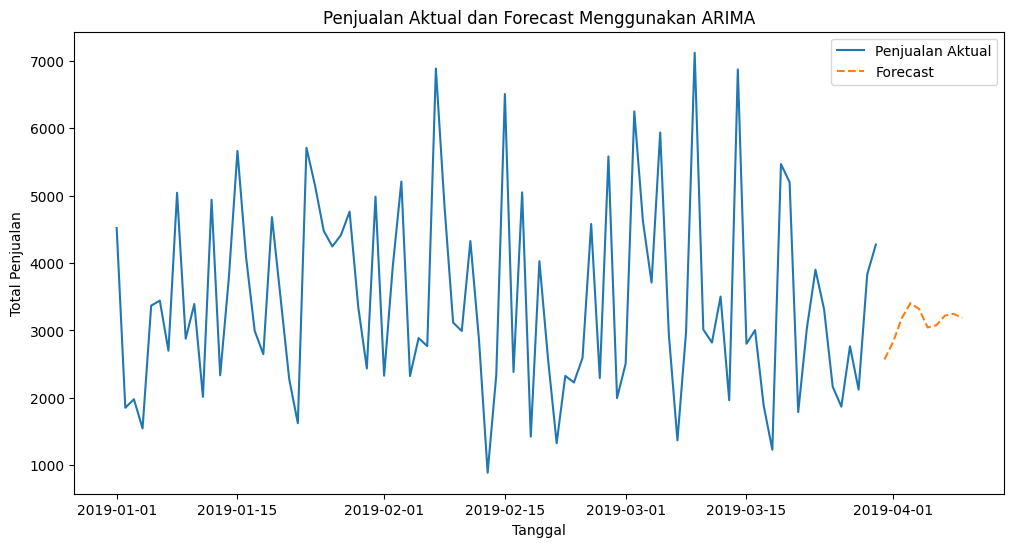

In [8]:
plt.figure(figsize=(12, 6))
plt.plot(df_sales, label='Penjualan Aktual')
plt.plot(forecast, label='Forecast', linestyle='--')
plt.title('Penjualan Aktual dan Forecast Menggunakan ARIMA')
plt.xlabel('Tanggal')
plt.ylabel('Total Penjualan')
plt.legend()
plt.show()

In [15]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_percentage_error
import warnings
import itertools

warnings.filterwarnings('ignore')

df = pd.read_csv('data/supermarket.csv')

# Mengonversi kolom 'Date' menjadi tipe datetime
df['Date'] = pd.to_datetime(df['Date'])

# Menambahkan kolom total penjualan (Unit price * Quantity)

df['Total Sales'] = df['Unit price'] * df['Quantity']

# Menyusun data penjualan berdasarkan tanggal
df_sales = df[['Date', 'Total Sales']].set_index('Date').resample('D').sum()
df_sales

# Menghitung IQR untuk mendeteksi outlier
Q1 = df_sales['Total Sales'].quantile(0.25)
Q3 = df_sales['Total Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menghapus outlier
df_clean = df_sales[(df_sales['Total Sales'] >= lower_bound) & (df_sales['Total Sales'] <= upper_bound)]

# Function to find the best ARIMA model parameters
def find_best_arima(df_clean, p_values, d_values, q_values, max_mape=0.50):
    best_score, best_order = float("inf"), None
    
    for p, d, q in itertools.product(p_values, d_values, q_values):
        try:
            model = ARIMA(df_clean, order=(p, d, q))
            model_fit = model.fit()
            # Menggunakan MAPE untuk memilih model terbaik
            mape = mean_absolute_percentage_error(df_clean['Total Sales'], model_fit.fittedvalues)
            if mape < best_score and mape < max_mape:
                best_score, best_order = mape, (p, d, q)
        except:
            continue
    return best_order, best_score

# Parameter ranges to try
p_values = range(0, 5)
d_values = range(0, 5)
q_values = range(0, 5)

# Find the best ARIMA parameters
best_order, best_score = find_best_arima(df_clean, p_values, d_values, q_values)

if best_order is not None:
    print(f'Best ARIMA order: {best_order} with MAPE: {best_score}')
    
    # Fit the best ARIMA model
    model = ARIMA(df_clean, order=best_order)
    model_fit = model.fit()
    
    # Membuat prediksi ke depan
    forecast = model_fit.forecast(steps=10)
    
    # Menghitung metrik evaluasi
    mape = mean_absolute_percentage_error(df_clean['Total Sales'], model_fit.fittedvalues)
    
    # Menampilkan hasil
    print(f'MAPE: {mape}')
else:
    print('No ARIMA model met the MAPE criterion of less than 50%')


Best ARIMA order: (3, 0, 3) with MAPE: 0.39716974716498304
MAPE: 0.39716974716498304


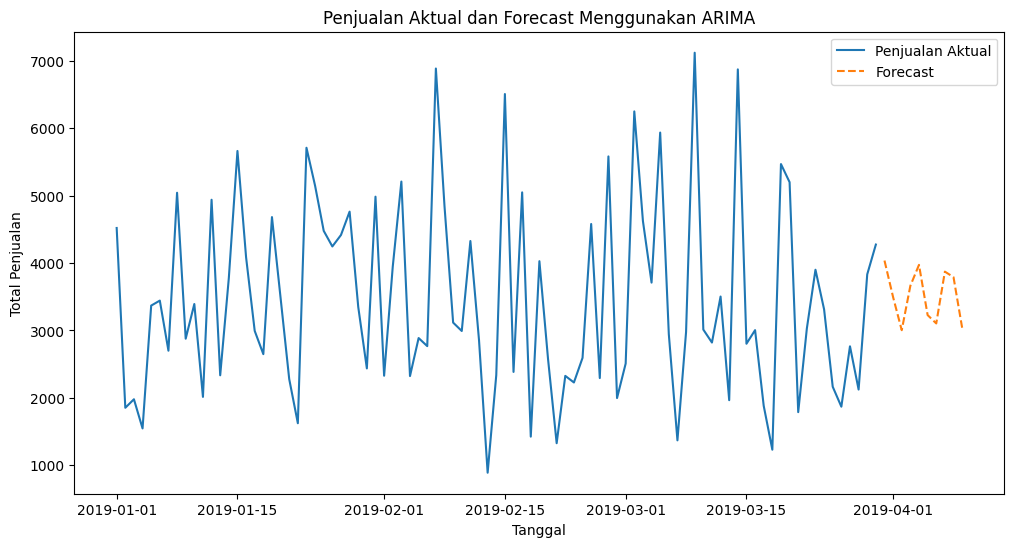

In [16]:
plt.figure(figsize=(12, 6))
plt.plot(df_sales, label='Penjualan Aktual')
plt.plot(forecast, label='Forecast', linestyle='--')
plt.title('Penjualan Aktual dan Forecast Menggunakan ARIMA')
plt.xlabel('Tanggal')
plt.ylabel('Total Penjualan')
plt.legend()
plt.show()

SARIMA

In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_percentage_error
import warnings
import itertools

warnings.filterwarnings('ignore')

df = pd.read_csv('data/supermarket.csv')

# Mengonversi kolom 'Date' menjadi tipe datetime
df['Date'] = pd.to_datetime(df['Date'])

# Menambahkan kolom total penjualan (Unit price * Quantity)
df['Total Sales'] = df['Unit price'] * df['Quantity']

# Menyusun data penjualan berdasarkan tanggal
df_sales = df[['Date', 'Total Sales']].set_index('Date').resample('D').sum()

# Menghitung IQR untuk mendeteksi outlier
Q1 = df_sales['Total Sales'].quantile(0.25)
Q3 = df_sales['Total Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menghapus outlier
df_clean = df_sales[(df_sales['Total Sales'] >= lower_bound) & (df_sales['Total Sales'] <= upper_bound)]

# Function to find the best SARIMA model parameters
def find_best_sarima(df_clean, p_values, d_values, q_values, P_values, D_values, Q_values, s, max_mape=0.50):
    best_score, best_order = float("inf"), None
    
    for p, d, q, P, D, Q in itertools.product(p_values, d_values, q_values, P_values, D_values, Q_values):
        try:
            model = SARIMAX(df_clean, order=(p, d, q), seasonal_order=(P, D, Q, s))
            model_fit = model.fit(disp=False)
            # Menggunakan MAPE untuk memilih model terbaik
            mape = mean_absolute_percentage_error(df_clean['Total Sales'], model_fit.fittedvalues)
            if mape < best_score and mape < max_mape:
                best_score, best_order = mape, (p, d, q, P, D, Q)
        except:
            continue
    return best_order, best_score

# Parameter ranges to try
p_values = range(0, 3)
d_values = range(0, 2)
q_values = range(0, 3)
P_values = range(0, 3)
D_values = range(0, 2)
Q_values = range(0, 3)

# Panjang periode musiman (misalnya, 7 untuk mingguan, 12 untuk bulanan, 365 untuk tahunan)
seasonal_period = 7  # Ubah sesuai data Anda

# Find the best SARIMA parameters
best_order, best_score = find_best_sarima(df_clean, p_values, d_values, q_values, P_values, D_values, Q_values, seasonal_period)

if best_order is not None:
    print(f'Best SARIMA order: {best_order} with MAPE: {best_score}')
    
    # Fit the best SARIMA model
    model = SARIMAX(df_clean, order=best_order[:3], seasonal_order=best_order[3:] + (seasonal_period,))
    model_fit = model.fit(disp=False)
    
    # Membuat prediksi ke depan
    forecast = model_fit.forecast(steps=100)
    
    # Menghitung metrik evaluasi
    mape = mean_absolute_percentage_error(df_clean['Total Sales'], model_fit.fittedvalues)
    
    # Menampilkan hasil
    print(f'MAPE: {mape}')
else:
    print('No SARIMA model met the MAPE criterion of less than 50%')


Best SARIMA order: (1, 1, 1, 2, 0, 2) with MAPE: 0.41518662986560934
MAPE: 0.41518662986560934


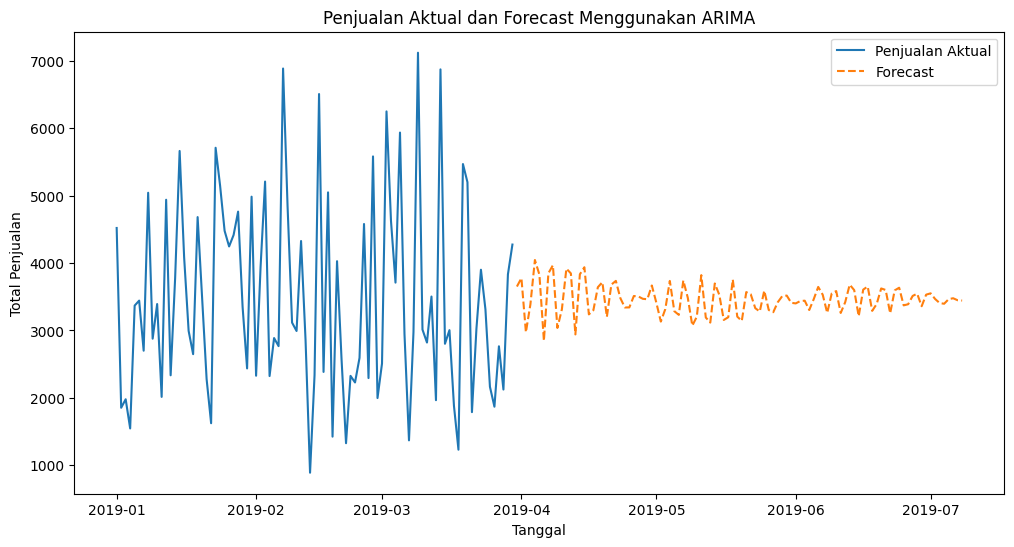

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(df_sales, label='Penjualan Aktual')
plt.plot(forecast, label='Forecast', linestyle='--')
plt.title('Penjualan Aktual dan Forecast Menggunakan ARIMA')
plt.xlabel('Tanggal')
plt.ylabel('Total Penjualan')
plt.legend()
plt.show()